<a href="https://colab.research.google.com/github/DibikshyaShrestha20/Gate-Location-Finding/blob/main/Gate_Location_Finding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# MountINg Drive
from google.colab import drive
import os, glob, zipfile
drive.mount('/content/drive', force_remount=False)
WORK = '/content/drive/MyDrive/KMC_TRIAL/PROJECTED'
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
print('Working in:', WORK)


Mounted at /content/drive
Working in: /content/drive/MyDrive/KMC_TRIAL/PROJECTED


In [ ]:
!pwd

/content/drive/MyDrive/KMC_TRIAL/PROJECTED


Original buildings geometry: ['Polygon']
Roads columns: ['__GID', 'OBJECT_ID', 'FID_KV_ROA', 'SUR_TYPE', 'PAVE_TYPE', 'START_END', 'STATUS', 'REMARKS', 'LINKNAME', 'ROADCLASS', 'ROADNAME', 'RW_CAT', 'NEPALI_NAM', 'KVMP_NAM', 'SCIENTI_NA', 'GLD', 'ROW', 'FOOT_WIDTH', 'PRESENT_SI', 'RECOMMEND', 'LENGTH', 'ROAD_WIDTH', 'GEOMETRY', 'ROAD_ID', 'ROAD_CLASS', 'ROAD_CODE', 'Rank_Lengt', 'LENGTH_INT', 'ORIG_FID', 'Roa_Cod_II', 'geometry']
Road classes: ['C' 'D' None]
After boundary explode: ['LineString']
Total building edges: 2034
Unique buildings: 317
Saved all midpoints: 2034

Processing buildings to select final midpoints...

✅ DONE
Total buildings processed: 317
Final midpoints selected: 317
Saved: building_final_midpoints.shp
Saved: building_edges.shp


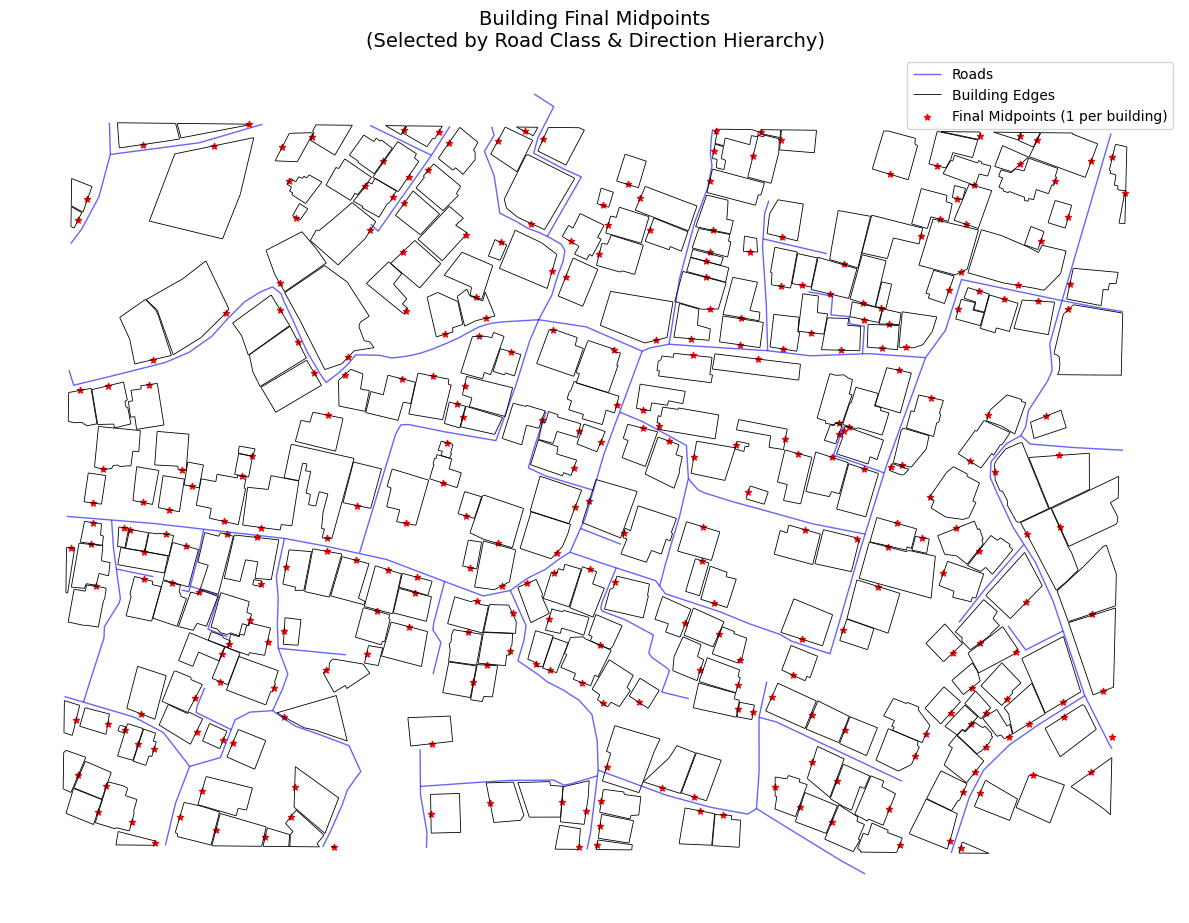


Visualization saved as: final_midpoints_map.png


In [ ]:


import geopandas as gpd
from shapely.geometry import LineString, Point
from shapely.ops import nearest_points
import pandas as pd
import os
import numpy as np


buildings_path = "buildings.shp"
road_path = "road.shp"
if not os.path.exists(buildings_path):
    raise FileNotFoundError(f"Error: {buildings_path} not found. Please upload it to {os.getcwd()}")
if not os.path.exists(road_path):
    raise FileNotFoundError(f"Error: {road_path} not found. Please upload it to {os.getcwd()}")
#Loading Buildings and Roads
buildings = gpd.read_file(buildings_path)
roads = gpd.read_file(road_path)
print("Original buildings geometry:", buildings.geom_type.unique())
print("Roads columns:", roads.columns.tolist())
print("Road classes:", roads['ROAD_CLASS'].unique() if 'ROAD_CLASS' in roads.columns else "ROAD_CLASS not found!")


if buildings.crs != roads.crs:
    roads = roads.to_crs(buildings.crs)

buildings['bldg_id'] = buildings.index
buildings["geometry"] = buildings.geometry.boundary
buildings_exploded = buildings.explode(index_parts=False).reset_index(drop=True)
print("After boundary explode:", buildings_exploded.geom_type.unique())

edges = []

for idx, row in buildings_exploded.iterrows():
    line = row.geometry
    coords = list(line.coords)

    for i in range(len(coords) - 1):
        edge = LineString([coords[i], coords[i + 1]])
        edges.append({
            "geometry": edge,
            "bldg_id": row['bldg_id'],

        })

edges_gdf = gpd.GeoDataFrame(edges, crs=buildings.crs)

print("Total building edges:", len(edges_gdf))
print("Unique buildings:", edges_gdf['bldg_id'].nunique())

#Computing the midpoint of buildingd
def edge_midpoint(line):
    return line.interpolate(line.length / 2)


edges_gdf["edge_geometry"] = edges_gdf["geometry"]
edges_gdf["midpoint"] = edges_gdf["edge_geometry"].apply(edge_midpoint)


all_midpoints = gpd.GeoDataFrame({
    'bldg_id': edges_gdf['bldg_id'],
    'geometry': edges_gdf['midpoint']
}, crs=edges_gdf.crs)

all_midpoints.to_file("all_building_edge_midpoints.shp")
print("Saved all midpoints:", len(all_midpoints))

edges_gdf["geometry"] = edges_gdf["midpoint"]



# Road class hierarchy
ROAD_HIERARCHY = {'A': 1, 'B': 2, 'C': 3, 'D': 4}

# Direction hierarchy
    'East': 0,
    'SouthEast': 1,
    'South': 2,
    'North': 3,
    'West': 4
}

def get_cardinal_direction(angle_degrees):
    """Convert angle (0=East, 90=North, 180=West, 270=South) to cardinal direction"""

    angle = angle_degrees % 360


    if 337.5 <= angle or angle < 22.5:
        return 'East'
    elif 22.5 <= angle < 67.5:
        return 'NorthEast'
    elif 67.5 <= angle < 112.5:
        return 'North'
    elif 112.5 <= angle < 157.5:
        return 'NorthWest'
    elif 157.5 <= angle < 202.5:
        return 'West'
    elif 202.5 <= angle < 247.5:
        return 'SouthWest'
    elif 247.5 <= angle < 292.5:
        return 'South'
    elif 292.5 <= angle < 337.5:
        return 'SouthEast'
    return 'East'

def map_to_hierarchy_direction(direction):
    """Map any direction to hierarchy direction"""
    mapping = {
        'East': 'East',
        'SouthEast': 'SouthEast',
        'South': 'South',
        'North': 'North',
        'West': 'West',
        'NorthEast': 'East',
        'NorthWest': 'North',
        'SouthWest': 'South'
    }
    return mapping.get(direction, 'East')

def get_line_angle(line):
    """Get angle of line in degrees (0=East, 90=North)"""
    if line.geom_type == 'MultiLineString':

        if not line.is_empty and len(line.geoms) > 0:
            line = line.geoms[0]
        else:
            return 0

    coords = list(line.coords)
    if len(coords) < 2:
        return 0


    x1, y1 = coords[0][0], coords[0][1]
    x2, y2 = coords[-1][0], coords[-1][1]

    angle = np.degrees(np.arctan2(y2 - y1, x2 - x1))
    return angle % 360

def perpendicular_distance(point, line):
    """Calculate perpendicular distance from point to line"""
    return point.distance(line)

def find_nearest_roads(midpoint, roads_gdf, max_distance=100):
    """Find roads within max_distance of midpoint"""

    buffer = midpoint.buffer(max_distance)
    nearby = roads_gdf[roads_gdf.intersects(buffer)]

    if len(nearby) == 0:
        return gpd.GeoDataFrame()


    nearby = nearby.copy()
    nearby['dist'] = nearby.geometry.apply(lambda x: perpendicular_distance(midpoint, x))
    return nearby.sort_values('dist')

def is_near_intersection(midpoint, roads_gdf, buffer_distance=50):
    """Check if midpoint is near a road intersection"""
    buffer = midpoint.buffer(buffer_distance)
    nearby_roads = roads_gdf[roads_gdf.intersects(buffer)]

    if len(nearby_roads) < 2:
        return False, gpd.GeoDataFrame()


    intersections = []
    road_geoms = nearby_roads.geometry.tolist()

    for i in range(len(road_geoms)):
        for j in range(i+1, len(road_geoms)):
            if road_geoms[i].intersects(road_geoms[j]):
                inter = road_geoms[i].intersection(road_geoms[j])
                if not inter.is_empty:
                    if inter.geom_type == 'Point':
                        intersections.append(inter)
                    elif inter.geom_type == 'MultiPoint':
                        intersections.extend(list(inter.geoms)
)

    if intersections:

        for inter in intersections:
            if midpoint.distance(inter) < buffer_distance:
                return True, nearby_roads

    return False, nearby_roads

def select_midpoint_for_building(bldg_id, bldg_edges, roads_gdf):
    """
    Select one midpoint for a building based on:
    1. If near intersection: choose based on road class hierarchy and direction
    2. If single road: choose shortest perpendicular distance
    """


    test_point = bldg_edges.iloc[0]['midpoint']
    is_intersection, nearby_roads = is_near_intersection(test_point, roads_gdf)

    results = []

    for idx, row in bldg_edges.iterrows():
        midpoint = row['midpoint']


        nearest = find_nearest_roads(midpoint, roads_gdf, max_distance=100)

        if len(nearest) == 0:
            continue

        # Get closest road
        closest_road = nearest.iloc[0]
        min_dist = closest_road['dist']
        road_class = closest_road.get('ROAD_CLASS', 'D')

        results.append({
            'midpoint': midpoint,
            'edge_idx': idx,
            'min_dist': min_dist,
            'road_class': road_class,
            'road_class_rank': ROAD_HIERARCHY.get(road_class, 5),
            'road_angle': get_line_angle(closest_road.geometry),
            'is_intersection': is_intersection,
            'num_roads': len(nearby_roads)
        })

    if not results:
        return None

    results_df = pd.DataFrame(results)

    # CASE 1: Near intersection with multiple roads
    if is_intersection and len(nearby_roads) >= 2:
        # Get unique road classes at intersection
        road_classes = nearby_roads['ROAD_CLASS'].unique() if 'ROAD_CLASS' in nearby_roads.columns else ['D']

        if len(road_classes) > 1:
            # Find highest class road
            best_class = min(road_classes, key=lambda x: ROAD_HIERARCHY.get(x, 5))


            best_roads = nearby_roads[nearby_roads['ROAD_CLASS'] == best_class]

            # Among midpoints, find those closest to best class roads
            results_df['to_best_class'] = results_df.apply(
                lambda r: min([perpendicular_distance(r['midpoint'], road)
                              for road in best_roads.geometry]) if len(best_roads) > 0 else 9999,
                axis=1
            )

            # Select midpoint with shortest distance to best class road
            best = results_df.loc[results_df['to_best_class'].idxmin()]
            return best['midpoint']

        else:

            results_df['direction'] = results_df['road_angle'].apply(
                lambda a: map_to_hierarchy_direction(get_cardinal_direction(a))
            )
            results_df['dir_rank'] = results_df['direction'].map(DIRECTION_HIERARCHY)


            results_df = results_df.sort_values(['dir_rank', 'min_dist'])
            return results_df.iloc[0]['midpoint']


    else:
        # Choose midpoint with shortest perpendicular offset to road
        best = results_df.loc[results_df['min_dist'].idxmin()]
        return best['midpoint']



print("\nProcessing buildings to select final midpoints...")

final_midpoints = []

for bldg_id in edges_gdf['bldg_id'].unique():

    bldg_edges = edges_gdf[edges_gdf['bldg_id'] == bldg_id].copy()

    # Select best midpoint
    selected = select_midpoint_for_building(bldg_id, bldg_edges, roads)

    if selected is not None:
        final_midpoints.append({
            'bldg_id': bldg_id,
            'geometry': selected
        })


final_midpoints_gdf = gpd.GeoDataFrame(final_midpoints, crs=edges_gdf.crs)

print(f"\n✅ DONE")
print(f"Total buildings processed: {len(edges_gdf['bldg_id'].unique())}")
print(f"Final midpoints selected: {len(final_midpoints_gdf)}")

# Save results
final_midpoints_gdf.to_file("building_final_midpoints.shp")
print("Saved: building_final_midpoints.shp")


edges_save_gdf = gpd.GeoDataFrame({
    'bldg_id': edges_gdf['bldg_id'],
    'geometry': edges_gdf['edge_geometry']
}, crs=edges_gdf.crs)

edges_save_gdf.to_file("building_edges.shp")
print("Saved: building_edges.shp")

#Visualization

import matplotlib.pyplot as plt


edges_plot = gpd.read_file("building_edges.shp")
midpoints_plot = gpd.read_file("building_final_midpoints.shp")
fig, ax = plt.subplots(1, 1, figsize=(12, 12))
if not roads.empty:
    roads.plot(ax=ax, color='blue', linewidth=1, alpha=0.6, label='Roads')
edges_plot.plot(
    ax=ax,
    linewidth=0.6,
    edgecolor="black",
    label="Building Edges"
)
midpoints_plot.plot(
    ax=ax,
    color="red",
    markersize=20,
    marker='*',
    label="Final Midpoints (1 per building)"
)

# Styling
ax.set_title("Building Final Midpoints\n(Selected by Road Class & Direction Hierarchy)", fontsize=14)
ax.set_axis_off()
ax.legend()

plt.tight_layout()
plt.savefig("final_midpoints_map.png", dpi=150, bbox_inches='tight')
plt.show()

print("\nVisualization saved as: final_midpoints_map.png")
